In [12]:
"""CAMELS-MX streamflow quality control, suitable for Jupyter %run.

Dependencies: pandas, numpy, matplotlib; pyarrow for Parquet.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def load_streamflow(path, date_col='datetime', flow_col='streamflow', date_format=None,
                    hour_col=None, hour_unit='h', dayfirst=False):
    """Load CSV/Parquet, standardize datetime and streamflow; retain all other columns.

    hour_col is optional and added to the parsed date (e.g. pk_hora).
    Duplicate dates are retained for QC, not silently removed.
    """
    path = Path(path)
    if path.suffix.lower() == '.csv':
        df = pd.read_csv(path)
    elif path.suffix.lower() in ('.parquet', '.pq'):
        df = pd.read_parquet(path)
        df.rename(columns={'gasto': 'streamflow'}, inplace=True)
        return df 
    else:
        raise ValueError('Expected a .csv or .parquet file')
    for col in (date_col, flow_col):
        if col not in df.columns:
            raise KeyError(f'Missing column: {col}. Available: {list(df.columns)}')
    dates = pd.to_datetime(df[date_col], format=date_format, dayfirst=dayfirst, errors='coerce')
    if hour_col is not None:
        if hour_col not in df:
            raise KeyError(f'Missing hour column: {hour_col}')
        dates = dates + pd.to_timedelta(pd.to_numeric(df[hour_col], errors='coerce'), unit=hour_unit)
    df = df.copy()
    df['datetime'] = dates
    df['streamflow'] = pd.to_numeric(df[flow_col], errors='coerce')
    return df.sort_values('datetime', kind='stable').reset_index(drop=True)


def infer_resolution(df):
    dates = pd.DatetimeIndex(df['datetime'].dropna().drop_duplicates().sort_values())
    if len(dates) < 2:
        return 'unknown', None
    deltas = pd.Series(dates).diff().dropna()
    step = deltas.mode().iloc[0]
    # Calendar-month spacing varies (28-31 days).
    if (deltas.dt.days.between(28, 31) & (deltas == pd.to_timedelta(deltas.dt.days, unit='D'))).mean() > .8:
        return 'monthly', None
    if step < pd.Timedelta(hours=1):
        label = 'sub-hourly'
    elif step == pd.Timedelta(hours=1):
        label = 'hourly'
    elif step == pd.Timedelta(days=1):
        label = 'daily'
    else:
        label = f'{step} (modal interval)'
    return label, step


def quality_control(df, flatline_length=6):
    """Flag suspicious observations without dropping rows or existing source flags."""
    if flatline_length < 2:
        raise ValueError('flatline_length must be >= 2')
    out = df.copy()
    q = pd.to_numeric(out['streamflow'], errors='coerce')
    out['flag_negative'] = q < 0
    out['flag_duplicate_date'] = out['datetime'].duplicated(keep=False) & out['datetime'].notna()
    out['flag_invalid_date'] = out['datetime'].isna()
    out['streamflow_qc'] = q.mask(out['flag_negative'])
    clean = out['streamflow_qc']
    mu, sd = clean.mean(), clean.std()
    for n in (1, 2, 3):
        out[f'flag_outlier_{n}sd'] = ((clean - mu).abs() > n * sd) if pd.notna(sd) and sd > 0 else False
    # Consecutive identical values, separated by neither NaNs nor gaps in time.
    _, step = infer_resolution(out)
    equal = clean.eq(clean.shift()) & clean.notna()
    if step is not None:
        equal &= out['datetime'].diff().eq(step)
    groups = (~equal).cumsum()
    sizes = groups.groupby(groups).transform('size')
    out['flag_flatline'] = (sizes >= flatline_length) & clean.notna()
    out['flag_missing'] = clean.isna()
    return out


def _expected_index(start, end, resolution, step):
    if resolution == 'monthly':
        return pd.date_range(start.to_period('M').to_timestamp(), end.to_period('M').to_timestamp(), freq='MS')
    if step is None or step <= pd.Timedelta(0):
        return pd.DatetimeIndex([])
    return pd.date_range(start, end, freq=step)


def summarize_streamflow(df):
    """One-row summary; calendar-year completeness requires every expected value."""
    if 'streamflow_qc' not in df:
        df = quality_control(df)
    valid = df.loc[df['datetime'].notna()].copy()
    resolution, step = infer_resolution(valid)
    if valid.empty:
        return pd.DataFrame([{'resolution': 'unknown', 'records': len(df)}])
    valid = valid.sort_values('datetime')
    start, end = valid['datetime'].iloc[0], valid['datetime'].iloc[-1]
    # Reindex unique observations for missing-timestamp accounting.
    unique = valid.drop_duplicates('datetime', keep='first').set_index('datetime')['streamflow_qc']
    expected = _expected_index(start, end, resolution, step)
    missing_timestamps = len(expected.difference(unique.index)) if len(expected) else np.nan
    complete_years = []
    for year in range(start.year, end.year + 1):
        if resolution == 'monthly':
            expected_year = pd.date_range(f'{year}-01-01', periods=12, freq='MS')
        elif step is not None and step <= pd.Timedelta(days=1):
            expected_year = pd.date_range(f'{year}-01-01', f'{year+1}-01-01', freq=step, inclusive='left')
        else:
            continue
        # Exact timestamp alignment: data with a non-midnight daily observation
        # should be standardized before assessing calendar completeness.
        if expected_year.isin(unique.index).all() and unique.reindex(expected_year).notna().all():
            complete_years.append(year)
    q = valid['streamflow_qc']
    result = {
        'first_year': start.year, 'last_year': end.year,
        'first_date': start, 'last_date': end,
        'resolution': resolution, 'modal_interval': str(step) if step is not None else 'calendar month / unknown',
        'records': len(df), 'complete_years': len(complete_years),
        'complete_year_list': complete_years,
        'nan_records': int(q.isna().sum()),
        'nan_percent': round(100 * q.isna().mean(), 2),
        'missing_timestamps': missing_timestamps,
        'negative_values': int(df['flag_negative'].sum()),
        'duplicate_date_records': int(df['flag_duplicate_date'].sum()),
        'flatline_records': int(df['flag_flatline'].sum()),
        'outliers_1sd': int(df['flag_outlier_1sd'].sum()),
        'outliers_2sd': int(df['flag_outlier_2sd'].sum()),
        'outliers_3sd': int(df['flag_outlier_3sd'].sum()),
        'min_flow': q.min(), 'max_flow': q.max(),
        'mean_flow': q.mean(), 'std_flow': q.std(),
    }
    return pd.DataFrame([result])


def compare_hourly_daily(hourly, daily, rtol=0.01, atol=0.0):
    """Compare daily discharge against mean hourly discharge (not sum)."""
    def series(df):
        col = 'streamflow_qc' if 'streamflow_qc' in df else 'streamflow'
        return df.dropna(subset=['datetime']).set_index('datetime')[col].sort_index()
    h = series(hourly)
    d = series(daily)
    hourly_mean = h.resample('D').mean()
    hourly_count = h.resample('D').count()
    daily_mean = d.resample('D').mean()
    result = pd.concat([daily_mean.rename('daily_observed'), hourly_mean.rename('daily_from_hourly'),
                        hourly_count.rename('valid_hourly_records')], axis=1)
    result['difference'] = result['daily_from_hourly'] - result['daily_observed']
    result['match'] = np.isclose(result['daily_from_hourly'], result['daily_observed'], rtol=rtol, atol=atol)
    result.loc[result[['daily_observed', 'daily_from_hourly']].isna().any(axis=1), 'match'] = False
    return result


def plot_streamflow_qc(df, station_name=None, figsize=(14, 13)):
    """Single 4-panel figure: series, seasonal cycle, subdaily cycle, duration curve."""
    if 'streamflow_qc' not in df:
        df = quality_control(df)
    data = df.dropna(subset=['datetime']).copy()
    q = data['streamflow_qc']
    t = data['datetime']
    fig, ax = plt.subplots(4, 1, figsize=figsize, constrained_layout=True)
    ax[0].plot(t, q, lw=.65)
    flagged = data['flag_outlier_3sd']
    ax[0].scatter(t[flagged], q[flagged], s=9, color='red', label='>3 SD')
    if flagged.any():
        ax[0].legend()
    ax[0].set_title('Full streamflow time series')
    ax[0].set_ylabel('Discharge')
    seasonal = data.assign(month=t.dt.month).groupby('month')['streamflow_qc'].agg(['median', 'mean'])
    ax[1].plot(seasonal.index, seasonal['median'], marker='o', label='Median')
    ax[1].plot(seasonal.index, seasonal['mean'], marker='o', label='Mean')
    ax[1].set_xticks(range(1, 13))
    ax[1].set_xlabel('Month')
    ax[1].set_ylabel('Discharge')
    ax[1].set_title('Seasonal cycle')
    ax[1].legend()
    resolution, _ = infer_resolution(data)
    if resolution in ('sub-hourly', 'hourly'):
        hour = t.dt.hour + t.dt.minute / 60 + t.dt.second / 3600
        diurnal = data.assign(hour=hour).groupby('hour')['streamflow_qc'].median()
        ax[2].plot(diurnal.index, diurnal.values, marker='.', lw=1)
        ax[2].set_xlim(0, 24)
        ax[2].set_xlabel('Hour of day')
        ax[2].set_ylabel('Median discharge')
        ax[2].set_title('Sub-daily cycle')
    else:
        ax[2].text(.5, .5, 'Not applicable to daily/monthly data', ha='center', va='center', transform=ax[2].transAxes)
        ax[2].set_title('Sub-daily cycle')
        ax[2].set_xticks([])
        ax[2].set_yticks([])
    sorted_q = np.sort(q.dropna().to_numpy())[::-1]
    if len(sorted_q):
        exceedance = 100 * np.arange(1, len(sorted_q) + 1) / (len(sorted_q) + 1)
        ax[3].plot(exceedance, sorted_q)
    ax[3].set_xlabel('Exceedance probability (%)')
    ax[3].set_ylabel('Discharge')
    ax[3].set_title('Flow-duration curve')
    ax[3].set_xlim(0, 100)
    for a in ax:
        a.grid(alpha=.25)
    if station_name:
        fig.suptitle(str(station_name), fontsize=15)
    return fig, ax


# Example for Jupyter (edit paths/column names):
# %run camels_mx_qc.py
# df = load_streamflow('/path/to/station.csv', date_col='pk_fecha',
#                      hour_col='pk_hora', flow_col='your_discharge_column',
#                      date_format='%m/%d/%y %H:%M:%S')
# qc = quality_control(df)
# display(summarize_streamflow(qc).T)
# fig, ax = plot_streamflow_qc(qc, station_name='Station 001')
# plt.show()


In [46]:
# ============================================================
# CAMELS-MX: Streamflow Quality Control
# ============================================================

# Configuration
path = "/Users/iaguirre/Documents/camels_mx_wip/bandas_dataset/Bases_Datos_Bandas_CSV/26057/HD26057.parquet"
station_name = "26057"

# 1. Load data
df = pd.read_parquet(path)

In [47]:
print(df.columns.tolist())
print('gasto' in df.columns)
print('streamflow' in df.columns)
df['streamflow'] = pd.to_numeric(df['ngasto'], errors='coerce')
df.index.name = "datetime_index" 
df["datetime"] = df.index
df.drop(columns=['ngasto'])

['ngasto']
False
False


,streamflow,datetime
datetime_index,,
1933-07-01 00:00:00,NaN,1933-07-01 00:00:00
1933-07-22 13:00:00,NaN,1933-07-22 13:00:00
1933-07-22 14:00:00,0.2360,1933-07-22 14:00:00
1933-07-22 15:00:00,0.2360,1933-07-22 15:00:00
1933-07-22 16:00:00,0.2360,1933-07-22 16:00:00
...,...,...
2006-12-29 18:00:00,0.2665,2006-12-29 18:00:00
2006-12-29 19:00:00,0.2658,2006-12-29 19:00:00
2006-12-30 08:00:00,0.2560,2006-12-30 08:00:00


In [37]:
df

,ngasto,streamflow,datetime
datetime_index,,,
1969-01-01 00:00:00,0.031,0.031,1969-01-01 00:00:00
1969-01-01 09:00:00,0.041,0.041,1969-01-01 09:00:00
1969-01-02 09:00:00,0.038,0.038,1969-01-02 09:00:00
1969-01-03 09:00:00,0.040,0.040,1969-01-03 09:00:00
1969-01-04 09:00:00,0.041,0.041,1969-01-04 09:00:00
...,...,...,...
2068-12-29 06:00:00,0.039,0.039,2068-12-29 06:00:00
2068-12-29 09:00:00,0.039,0.039,2068-12-29 09:00:00
2068-12-30 09:00:00,0.046,0.046,2068-12-30 09:00:00


,0
first_year,1933
last_year,2007
first_date,1933-07-01 00:00:00
last_date,2007-01-01 00:00:00
resolution,hourly
modal_interval,0 days 01:00:00
records,292628
complete_years,22
complete_year_list,"[1934, 1935, 1938, 1939, 1940, 1941, 1942, 194..."
nan_records,97


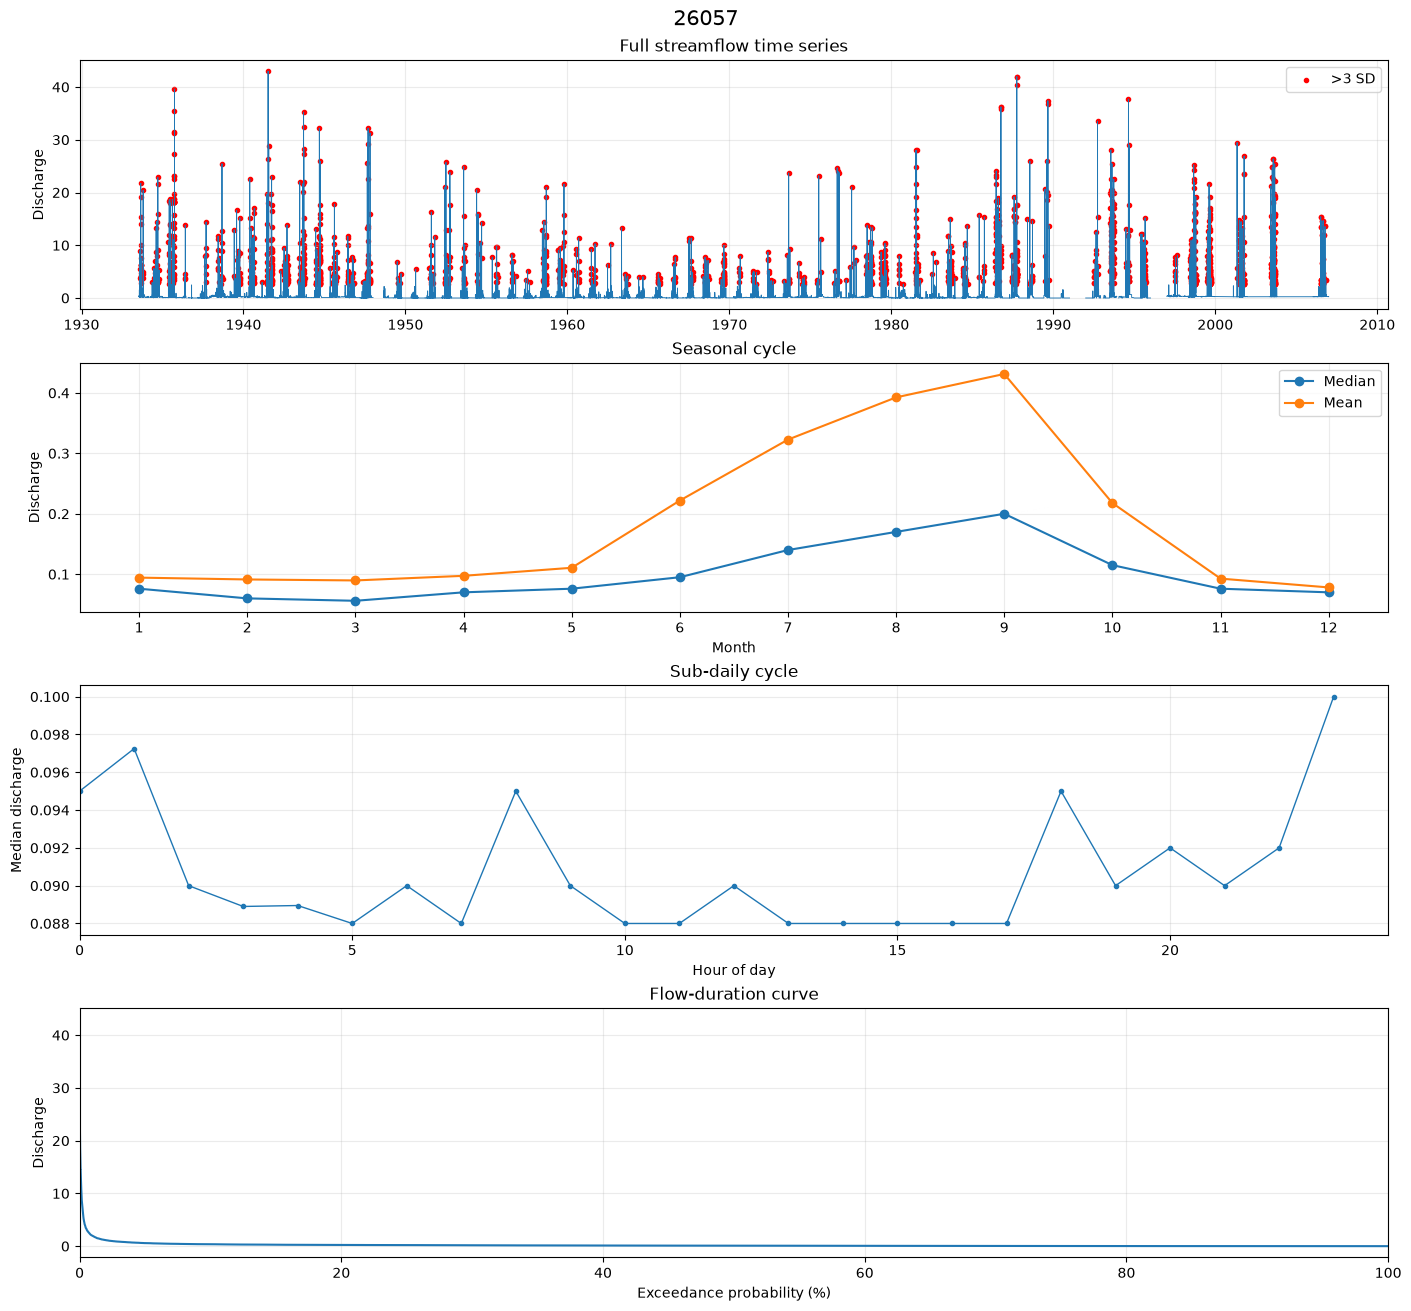

In [48]:
# 2. Quality control
qc = quality_control(
    df,
    flatline_length=6
)

# 3. Summary
summary = summarize_streamflow(qc)
display(summary.T)

# 4. Plots
fig, ax = plot_streamflow_qc(
    qc,
    station_name=station_name
)

plt.show()

In [39]:
df

,ngasto,streamflow,datetime
datetime_index,,,
1969-01-01 00:00:00,0.031,0.031,1969-01-01 00:00:00
1969-01-01 09:00:00,0.041,0.041,1969-01-01 09:00:00
1969-01-02 09:00:00,0.038,0.038,1969-01-02 09:00:00
1969-01-03 09:00:00,0.040,0.040,1969-01-03 09:00:00
1969-01-04 09:00:00,0.041,0.041,1969-01-04 09:00:00
...,...,...,...
2068-12-29 06:00:00,0.039,0.039,2068-12-29 06:00:00
2068-12-29 09:00:00,0.039,0.039,2068-12-29 09:00:00
2068-12-30 09:00:00,0.046,0.046,2068-12-30 09:00:00


In [40]:
df.describe()

,ngasto,streamflow,datetime
count,292531.000000,292531.000000,292628
mean,0.205793,0.205793,2037-06-15 00:02:41.553918
min,0.000000,0.000000,1969-01-01 00:00:00
25%,0.017000,0.017000,2035-08-17 10:45:00
50%,0.090000,0.090000,2046-05-03 22:30:00
75%,0.201000,0.201000,2055-10-02 13:15:00
max,43.000000,43.000000,2068-12-31 04:00:00
std,0.796178,0.796178,NaN


<Axes: >

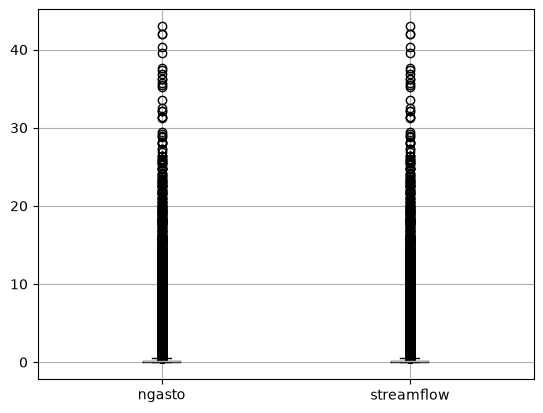

In [41]:
df.boxplot()

array([[<Axes: title={'center': 'ngasto'}>,
        <Axes: title={'center': 'streamflow'}>],
       [<Axes: title={'center': 'datetime'}>, <Axes: >]], dtype=object)

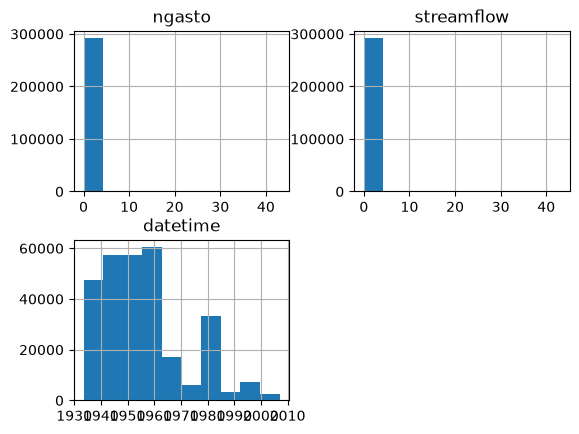

In [49]:
df.hist()